# WANDS data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rlt.data import load

products, queries, labels = load()
print(f"{len(products):,} products, {len(queries)} queries, {len(labels):,} labels")

42,994 products, 480 queries, 231,873 labels


## Labels

In [2]:
counts = labels["label"].value_counts()
pd.DataFrame({"labels": counts, "share": (counts / len(labels)).round(3)})

,labels,share
label,,
Partial,145678,0.628
Irrelevant,60723,0.262
Exact,25472,0.110


## Relevant products per query

In [3]:
per_query = (
    labels.pivot_table(index="query_id", columns="label", values="product_id", aggfunc="size")
    .reindex(queries.index)
    .fillna(0)
    .astype(int)
)
per_query["Exact + Partial"] = per_query["Exact"] + per_query["Partial"]
per_query[["Exact", "Exact + Partial"]].describe().round(1)

label,Exact,Exact + Partial
count,480.0,480.0
mean,53.1,356.6
std,105.3,535.5
min,0.0,0.0
25%,1.0,98.8
50%,10.0,170.0
75%,59.0,355.2
max,876.0,3495.0


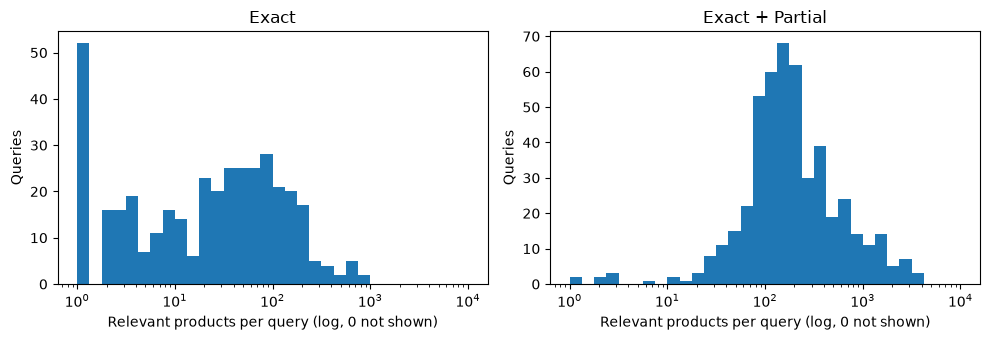

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, column in zip(axes, ["Exact", "Exact + Partial"]):
    ax.hist(per_query[column], bins=np.logspace(0, 4, 33))
    ax.set(title=column, xlabel="Relevant products per query (log, 0 not shown)", ylabel="Queries", xscale="log")
fig.tight_layout()
plt.show()

## Queries without an Exact product

In [5]:
no_exact = per_query["Exact"] == 0
print(f"{no_exact.sum()} of {len(per_query)} queries")
queries[no_exact].join(per_query).head(10)

101 of 480 queries


,query,query_class,Exact,Irrelevant,Partial,Exact + Partial
query_id,,,,,,
19,gurney slade 56,Chandeliers,0,4,10,10
23,stoneford end tables white and wood,End Tables,0,38,1228,1228
47,porcelain loaf pan,Bread & Loaf Pans,0,5,100,100
49,moen matte black hooks,Towel & Robe Hooks,0,19,116,116
52,westling coffee table,Coffee & Cocktail Tables,0,13,1420,1420
53,carolyn console table,Sofa & Console Tables,0,0,610,610
56,royal blue counter height chairs,Bar Stools,0,113,231,231
67,osgood mirror,Wall & Accent Mirrors,0,83,504,504
73,certified international melamine,Plates & Saucers,0,22,159,159


## Examples

In [6]:
queries.join(per_query).sample(8, random_state=0)

,query,query_class,Exact,Irrelevant,Partial,Exact + Partial
query_id,,,,,,
15,black 5 drawer dresser by guilford,Dressers & Chests,2,15,596,598
124,unique coffee tables,Coffee & Cocktail Tables,324,175,968,1292
141,podium with locking cabinet,Lecterns & Podiums,3,125,33,36
267,dolomite subway tile,Floor & Wall Tile,2,0,152,154
171,nectar queen mattress,Foam and Latex Mattresses,0,0,99,99
142,kitchen wooden stand,Specialty Serving,5,128,70,75
405,queen ann style living room chair,Accent Chairs,0,101,345,345
435,shoe closet,Shoe Storage,47,88,308,355
